# 01｜資料探索（EDA）：學餐人潮與品項需求

**目的**：在訓練模型之前，先了解資料長什麼樣子、有哪些規律，作為選擇特徵與模型的依據。

| 資料表 | 一列代表 | 目標變數 |
|---|---|---|
| `crowd.csv` | 某一天、某一餐、某個 30 分鐘時段 | `customers`：來客數 |
| `demand.csv` | 某一天、某一餐、某個品項 | `demand`：需求份數 |

> ⚠️ 本專題目前使用**模擬資料**（產生方式與假設見 `foodcast/data_generator.py`）。
> 這份 notebook 的重點是示範「拿到資料後應該怎麼分析」，換成真實資料後可以直接重跑。

**目錄**
1. 資料概況與品質檢查
2. 人潮的時間規律：時段、星期、學期
3. 特殊情境：考試週、國定假日、下雨
4. 天氣與品項偏好
5. 特徵相關性
6. 結論：對建模的啟示

In [1]:
import sys
from pathlib import Path

# 讓 notebook 可以 import 專案的 foodcast 套件（notebook 在 notebooks/ 資料夾裡）
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 中文字型：Windows 用微軟正黑體，Mac 用蘋方，Linux 用 Noto，依序找第一個有的
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "PingFang TC", "Noto Sans CJK TC", "Heiti TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False   # 負號正常顯示
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

from foodcast import config
from foodcast.train import load_data, time_split

## 1. 資料概況與品質檢查

In [2]:
crowd, demand = load_data()
print(f"crowd ：{crowd.shape[0]:,} 列 × {crowd.shape[1]} 欄，期間 {crowd['date'].min():%Y-%m-%d} ~ {crowd['date'].max():%Y-%m-%d}")
print(f"demand：{demand.shape[0]:,} 列 × {demand.shape[1]} 欄")
crowd.head()

crowd ：6,680 列 × 15 欄，期間 2024-09-01 ~ 2026-06-30
demand：8,016 列 × 20 欄


,date,meal,slot,customers,temp,rain_mm,has_event,weekday,is_weekend,is_holiday,month,in_semester,week,exam_week,pre_final
0,2024-09-01,午餐,11:00,9,27.5,0.0,0,6,1,0,9,0,0,0,0
1,2024-09-01,午餐,11:30,16,27.5,0.0,0,6,1,0,9,0,0,0,0
2,2024-09-01,午餐,12:00,29,27.5,0.0,0,6,1,0,9,0,0,0,0
3,2024-09-01,午餐,12:30,25,27.5,0.0,0,6,1,0,9,0,0,0,0
4,2024-09-01,午餐,13:00,12,27.5,0.0,0,6,1,0,9,0,0,0,0


In [3]:
# 缺失值與基本統計：確認資料沒有空值、數值範圍合理（人數不會是負的）
print("crowd 缺失值總數：", int(crowd.isna().sum().sum()))
print("demand 缺失值總數：", int(demand.isna().sum().sum()))
crowd[["customers", "temp", "rain_mm"]].describe().round(1)

crowd 缺失值總數： 0
demand 缺失值總數： 0


,customers,temp,rain_mm
count,6680.0,6680.0,6680.0
mean,131.7,22.0,4.3
std,112.1,5.0,9.3
min,5.0,10.3,0.0
25%,47.0,17.7,0.0
50%,102.0,22.7,0.0
75%,178.2,26.2,4.4
max,630.0,32.5,89.6


**觀察**：沒有缺失值，人數皆 ≥ 0。`customers` 的標準差很大（最小接近 0、最大超過 500），
代表不同日子、不同時段的人潮差異很大，這正是模型要學的東西。

## 2. 人潮的時間規律

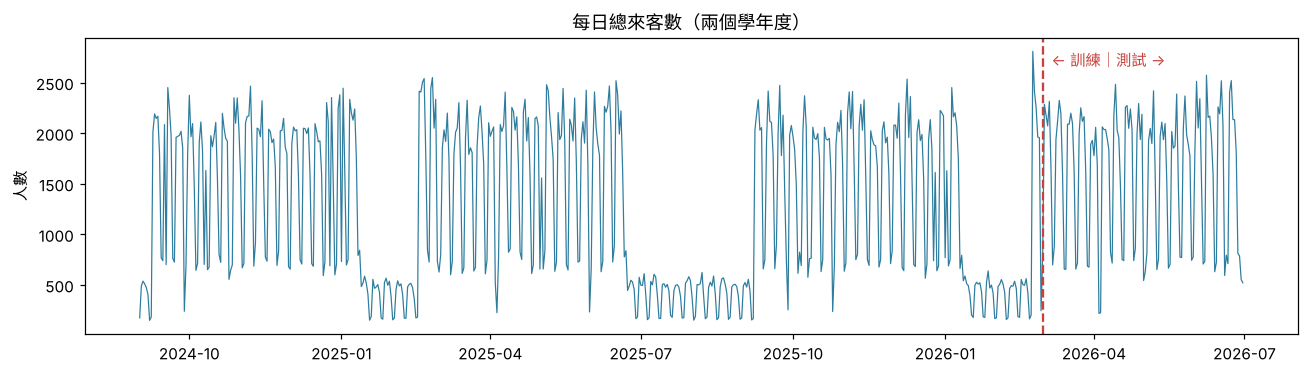

In [4]:
daily = crowd.groupby("date")["customers"].sum()

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(daily.index, daily.values, lw=0.8, color="#2E7D9E")
ax.axvline(pd.Timestamp(config.TEST_START), color="#C8423B", ls="--")
ax.text(pd.Timestamp(config.TEST_START), daily.max() * 0.95, "  ← 訓練｜測試 →", color="#C8423B")
ax.set_title("每日總來客數（兩個學年度）")
ax.set_ylabel("人數")
plt.tight_layout()
plt.show()

**觀察**：
- 寒暑假（每年 1 月下旬～2 月、7～8 月）人數明顯下降，曲線出現「凹谷」。
- 學期中呈現規律的鋸齒狀，代表有**每週循環**（平日多、週末少）。
- 紅線右邊是測試期間，模型訓練時看不到。

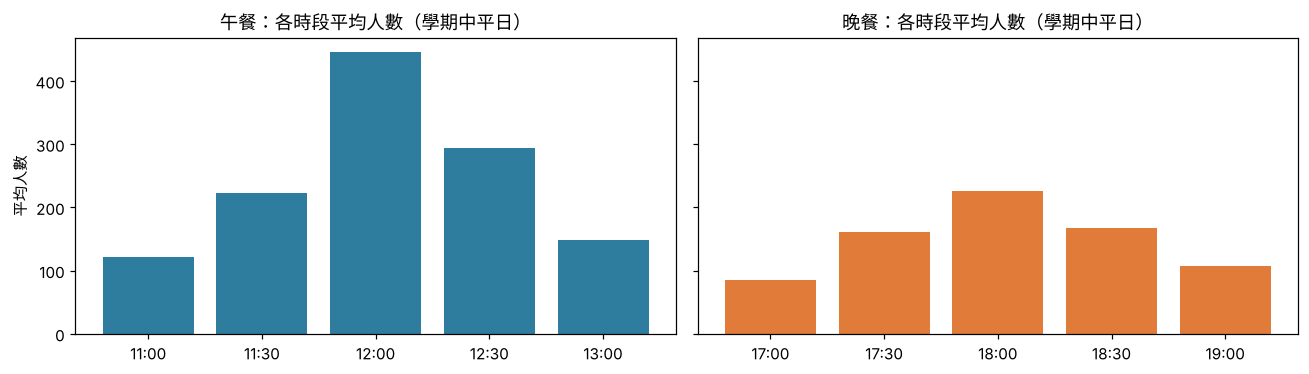

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
sem = crowd[(crowd["in_semester"] == 1) & (crowd["is_weekend"] == 0)]
for ax, meal in zip(axes, config.MEALS):
    s = sem[sem["meal"] == meal].groupby("slot")["customers"].mean()
    ax.bar(s.index, s.values, color="#2E7D9E" if meal == "午餐" else "#E07B39")
    ax.set_title(f"{meal}：各時段平均人數（學期中平日）")
axes[0].set_ylabel("平均人數")
plt.tight_layout()
plt.show()

**觀察**：午餐 12:00、晚餐 18:00 是尖峰，前後遞減，呈現**山形**。
→ 人數和時段**不是直線關係**，線性迴歸會很難學好，這是後面選擇樹模型的重要原因。

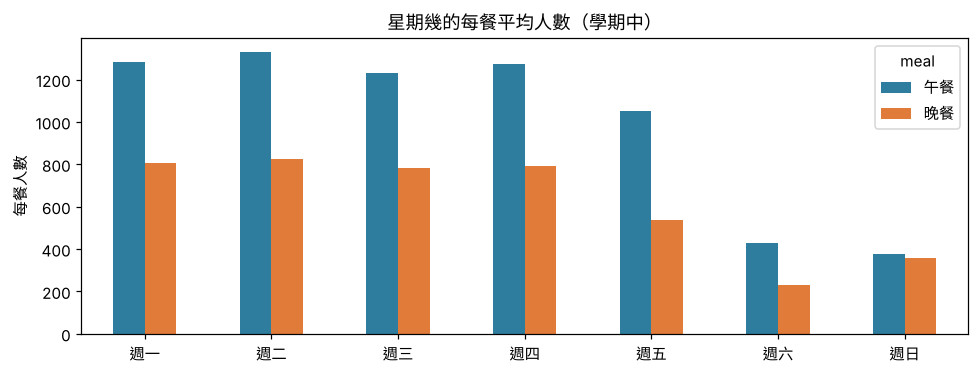

meal,午餐,晚餐
週一,1281.0,806.0
週二,1330.0,825.0
週三,1233.0,781.0
週四,1275.0,794.0
週五,1049.0,536.0
週六,426.0,230.0
週日,376.0,356.0


In [6]:
wk = (crowd[crowd["in_semester"] == 1]
      .groupby(["weekday", "meal"])["customers"].sum()
      / crowd[crowd["in_semester"] == 1].groupby(["weekday", "meal"])["date"].nunique()).unstack()
wk.index = [f"週{'一二三四五六日'[i]}" for i in wk.index]
ax = wk.plot(kind="bar", figsize=(9, 3.5), color=["#2E7D9E", "#E07B39"], rot=0)
ax.set_title("星期幾的每餐平均人數（學期中）")
ax.set_ylabel("每餐人數")
plt.tight_layout()
plt.show()
wk.round(0)

**觀察**：週一～週四差不多；**週五晚餐明顯下降**（很多人回家）；週末大幅減少，週日晚餐略回升（返校）。
→ 「星期幾」和「午餐/晚餐」之間有**交互作用**，週五只影響晚餐比較多。

## 3. 特殊情境：考試週、國定假日、下雨

In [7]:
sem_wd = crowd[(crowd["in_semester"] == 1) & (crowd["is_weekend"] == 0) & (crowd["is_holiday"] == 0)]
per_meal = sem_wd.groupby(["date", "meal", "exam_week"])["customers"].sum().reset_index()
exam = per_meal.groupby(["meal", "exam_week"])["customers"].mean().unstack()
exam.columns = ["一般週", "考試週"]
exam["變化 (%)"] = (100 * (exam["考試週"] / exam["一般週"] - 1)).round(1)
exam.round(0)

,一般週,考試週,變化 (%)
meal,,,
午餐,1264.0,1288.0,2.0
晚餐,758.0,853.0,12.0


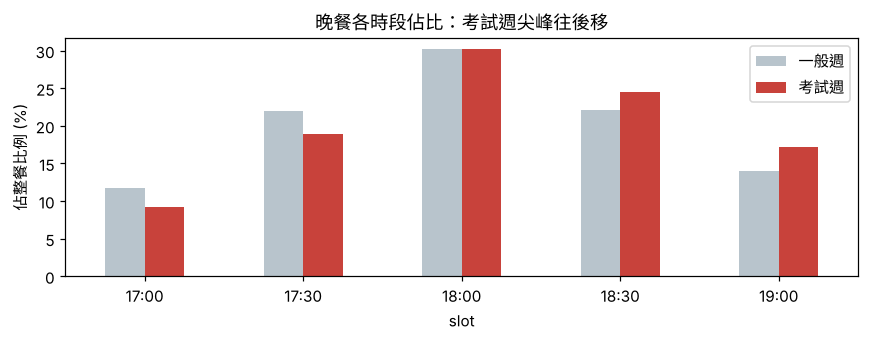

In [8]:
# 考試週晚餐的尖峰是否往後移？比較各時段佔整餐的比例
din = sem_wd[sem_wd["meal"] == "晚餐"]
share = din.groupby(["exam_week", "slot"])["customers"].sum()
share = (share / share.groupby(level=0).transform("sum") * 100).unstack(0)
share.columns = ["一般週", "考試週"]
ax = share.plot(kind="bar", figsize=(8, 3.2), rot=0, color=["#B8C4CC", "#C8423B"])
ax.set_title("晚餐各時段佔比：考試週尖峰往後移")
ax.set_ylabel("佔整餐比例 (%)")
plt.tight_layout()
plt.show()

In [9]:
# 國定假日、寒暑假 vs 一般平日
def day_type(r):
    if r["in_semester"] == 0:
        return "寒暑假"
    if r["is_holiday"] == 1:
        return "國定假日"
    if r["is_weekend"] == 1:
        return "週末"
    return "學期中平日"

days = crowd.groupby("date").agg(customers=("customers", "sum"), in_semester=("in_semester", "first"),
                                 is_holiday=("is_holiday", "first"), is_weekend=("is_weekend", "first"),
                                 rain_mm=("rain_mm", "first"))
days["類型"] = days.apply(day_type, axis=1)
days.groupby("類型")["customers"].agg(["count", "mean"]).rename(
    columns={"count": "天數", "mean": "平均每日人數"}).round(0).sort_values("平均每日人數")

,天數,平均每日人數
類型,,
寒暑假,164,403.0
國定假日,22,503.0
週末,136,722.0
學期中平日,346,2036.0


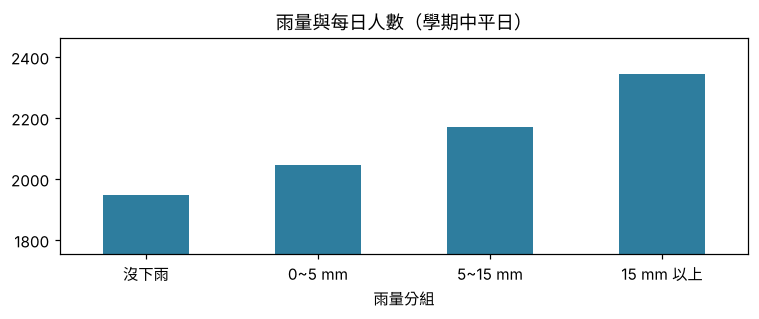

,天數,平均每日人數
雨量分組,,
沒下雨,213,1948.0
0~5 mm,47,2046.0
5~15 mm,48,2169.0
15 mm 以上,38,2345.0


In [10]:
# 下雨對人潮的影響：只看學期中平日，避免被假日干擾
wd = days[days["類型"] == "學期中平日"].copy()
wd["雨量分組"] = pd.cut(wd["rain_mm"], [-0.1, 0, 5, 15, 100], labels=["沒下雨", "0~5 mm", "5~15 mm", "15 mm 以上"])
rain = wd.groupby("雨量分組", observed=True)["customers"].agg(["count", "mean"]).round(0)
rain.columns = ["天數", "平均每日人數"]
ax = rain["平均每日人數"].plot(kind="bar", figsize=(7, 3), rot=0, color="#2E7D9E")
ax.set_ylim(rain["平均每日人數"].min() * 0.9, None)
ax.set_title("雨量與每日人數（學期中平日）")
plt.tight_layout()
plt.show()
rain

**觀察**：
- **考試週晚餐人數增加**，而且晚餐尖峰往後移（讀完書才去吃）。
- **國定假日、寒暑假**人數只有平日的一小部分，是很強的訊號。
- **雨越大，人越多**（少人外出覓食），但效果比行事曆小。
→ 行事曆特徵（考試週、假日、學期）和天氣特徵都應該放進模型。

## 4. 天氣與品項偏好

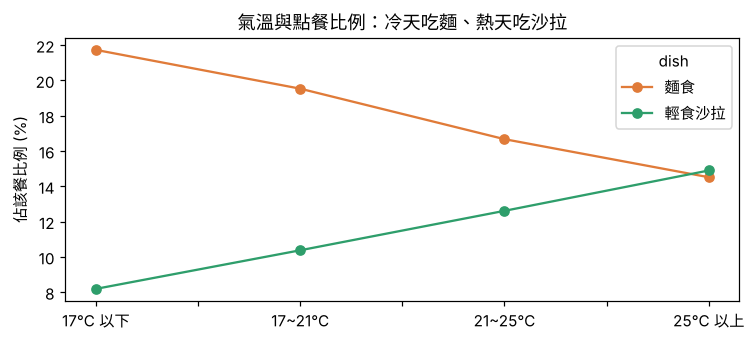

dish,便當,咖哩飯,素食,自助餐,輕食沙拉,麵食
氣溫分組,,,,,,
17°C 以下,20.4,11.8,8.0,29.9,8.2,21.7
17~21°C,20.2,11.9,8.0,30.0,10.4,19.5
21~25°C,20.6,12.0,8.0,30.1,12.6,16.7
25°C 以上,20.2,12.1,8.1,30.2,14.9,14.5


In [11]:
sem_d = demand[(demand["in_semester"] == 1) & (demand["is_weekend"] == 0)].copy()
sem_d["share"] = sem_d["demand"] / sem_d.groupby(["date", "meal"])["demand"].transform("sum")
sem_d["氣溫分組"] = pd.cut(sem_d["temp"], [0, 17, 21, 25, 40], labels=["17°C 以下", "17~21°C", "21~25°C", "25°C 以上"])
pref = sem_d.groupby(["氣溫分組", "dish"], observed=True)["share"].mean().unstack() * 100
ax = pref[["麵食", "輕食沙拉"]].plot(marker="o", figsize=(7, 3.2), color=["#E07B39", "#2E9E6B"])
ax.set_title("氣溫與點餐比例：冷天吃麵、熱天吃沙拉")
ax.set_ylabel("佔該餐比例 (%)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()
pref.round(1)

**觀察**：天冷時**麵食**比例上升，天熱時**輕食沙拉**比例上升。
→ 品項需求模型需要「氣溫」和「品項」的**交互作用**，同樣適合用樹模型。

## 5. 特徵相關性

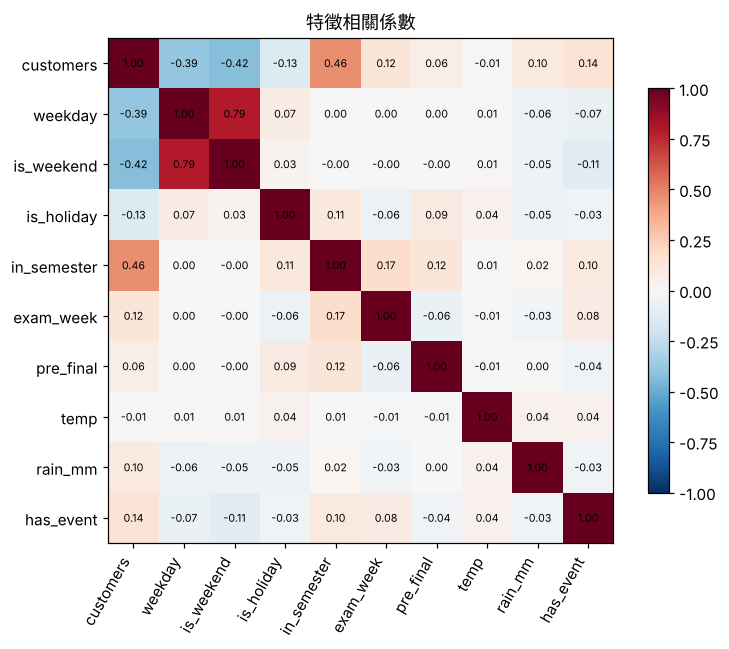

In [12]:
cols = ["customers", "weekday", "is_weekend", "is_holiday", "in_semester", "exam_week", "pre_final", "temp", "rain_mm", "has_event"]
corr = crowd[cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("特徵相關係數")
plt.tight_layout()
plt.show()

**觀察**：`in_semester`、`is_weekend` 和人數的相關最強。
但相關係數只能看**線性**關係，時段的山形效果、週五×晚餐這種交互作用都看不出來，
所以不能只靠相關係數挑特徵。

## 6. 結論：對建模的啟示

| 發現 | 對建模的影響 |
|---|---|
| 時段呈山形、週五只影響晚餐 | 關係是**非線性**且有**交互作用** → 選擇**樹模型**（隨機森林、梯度提升樹），並用線性迴歸當對照 |
| 寒暑假、假日、考試週影響很大 | 加入**行事曆特徵** |
| 下雨、氣溫有影響 | 加入**天氣特徵** |
| 資料有時間順序 | 訓練/測試要**依時間切分**，不能隨機打散 |
| 需求每天有隨機波動 | 備餐量用**分位數迴歸**，讓店家自己選要多保守 |

👉 下一份：`02_modeling.ipynb`